In [5]:
import pandas as pd

In [6]:
s=pd.read_csv("insurance.csv")
s

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [7]:
s.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [8]:
s.info

<bound method DataFrame.info of       age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]>

In [9]:
s.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
s.duplicated().sum()

np.int64(1)

In [11]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
x=s[['age']]
y=s[['charges']]

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [16]:
x_train

,age
560,46
1285,47
1142,52
969,39
486,54
...,...
1095,18
1130,39
1294,58
860,37


In [17]:
from sklearn.linear_model import LinearRegression

In [18]:
l=LinearRegression()
l.fit(x_train,y_train)

LinearRegression()

In [19]:
y_pred=l.predict(x_test)
y_pred

array([[14703.77387469],
       [12538.40483659],
       [19275.10851067],
       [14944.37043448],
       [ 8448.26332018],
       [12057.21171701],
       [ 8448.26332018],
       [19275.10851067],
       [10613.63235828],
       [15666.16011384],
       [11094.82547785],
       [13741.38763553],
       [10854.22891807],
       [14944.37043448],
       [18312.72227152],
       [15184.96699426],
       [15666.16011384],
       [15184.96699426],
       [14944.37043448],
       [14222.58075511],
       [ 9891.84267891],
       [14222.58075511],
       [ 8448.26332018],
       [ 9170.05299954],
       [15906.75667363],
       [16869.14291279],
       [18312.72227152],
       [10373.03579849],
       [15184.96699426],
       [ 8207.66676039],
       [13500.79107574],
       [17590.93259215],
       [ 8929.45643976],
       [11094.82547785],
       [10132.4392387 ],
       [14703.77387469],
       [ 8929.45643976],
       [14222.58075511],
       [16387.94979321],
       [12538.40483659],


In [47]:
y_test

,charges
764,9095.06825
887,5272.17580
890,29330.98315
1293,9301.89355
259,33750.29180
...,...
109,47055.53210
575,12222.89830
535,6067.12675
543,63770.42801


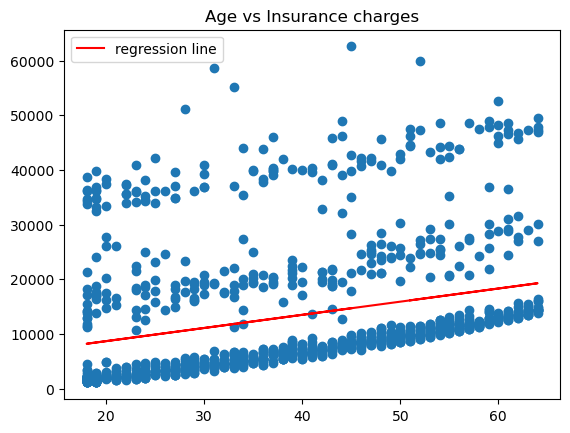

In [20]:
#Q1.does age affected insurance charges?
import matplotlib.pyplot as plt
plt.scatter(x_train,y_train)
plt.plot(x_test,y_pred,color='red',label="regression line")
plt.legend()
plt.title("Age vs Insurance charges")
plt.show()

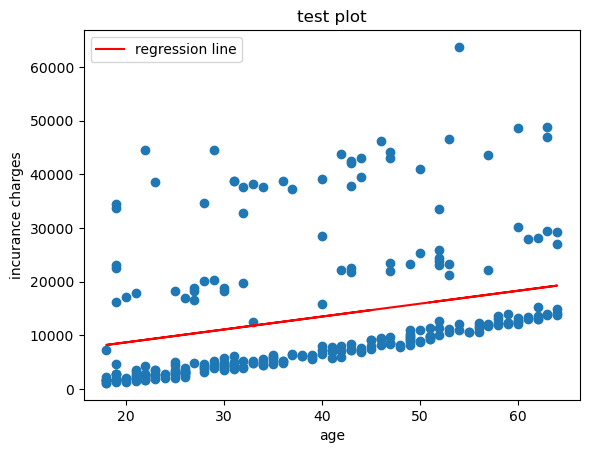

In [21]:
import matplotlib.pyplot as plt
plt.scatter(x_test,y_test)
plt.plot(x_test,y_pred,color='red',label="regression line")
plt.legend()
plt.title("test plot")
plt.xlabel("age")
plt.ylabel("incurance charges")
plt.show()

In [22]:
x=s[['bmi']]
y=s[['charges']]

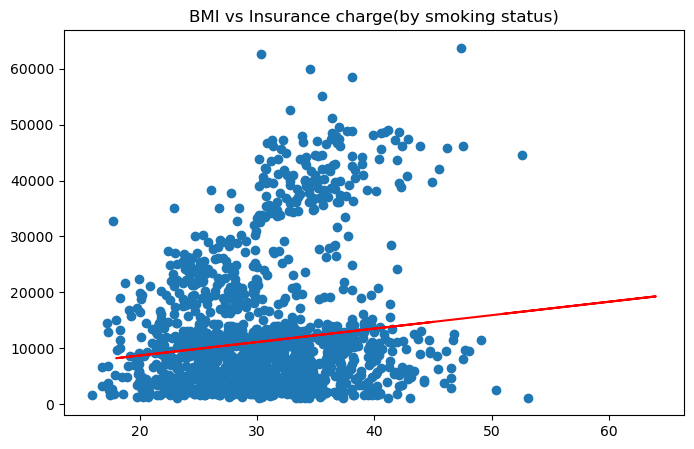

In [24]:
#Q2.how does BMI related to insurance costs?
plt.figure(figsize=(8,5))
plt.scatter(data=s,x="bmi",y="charges")
plt.plot(x_test,y_pred,color='red',label="regression line")
plt.title("BMI vs Insurance charge(by smoking status)")
plt.show()

In [30]:
x=s[["smoker"]]
y=s[["charges"]]

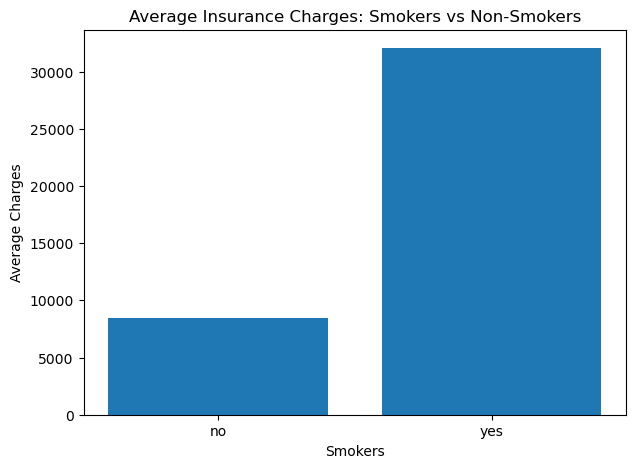

In [45]:
#Q3.do smokers have different average charges?

import matplotlib.pyplot as plt
smoker_charges = s.groupby('smoker')['charges'].mean()
plt.figure(figsize=(7, 5))
plt.bar(smoker_charges.index, smoker_charges.values)
plt.title("Average Insurance Charges: Smokers vs Non-Smokers")
plt.xlabel("Smokers")
plt.ylabel("Average Charges")
plt.show()

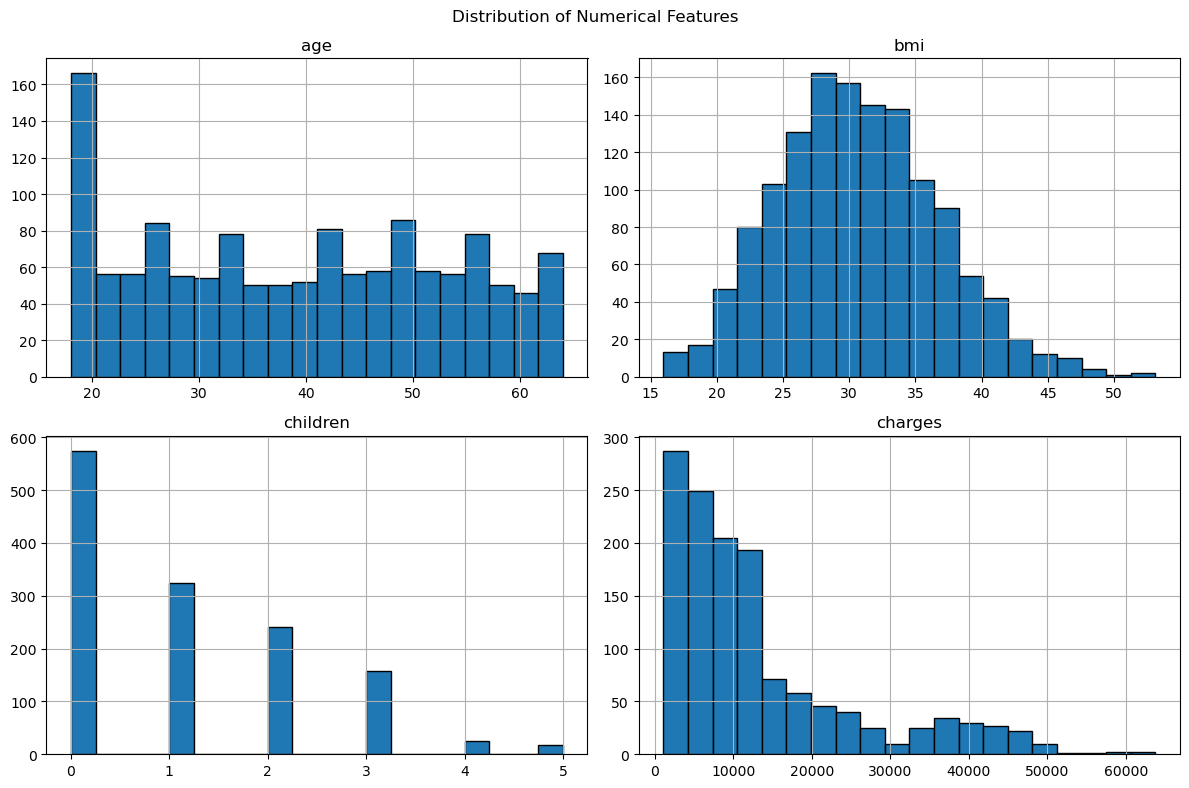

In [46]:
#Q4.performance Exploratory Data Analysis(EDA)
numeric_columns = ["age", "bmi", "children", "charges"]
s[numeric_columns].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

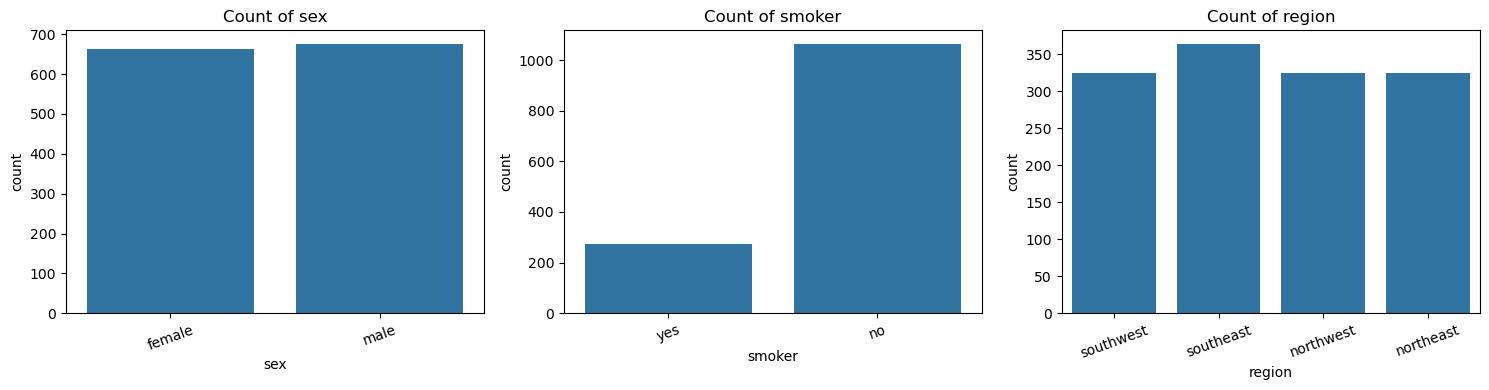

In [50]:
#Q4(B).Count plots for categorical columns
categorical_columns = ["sex", "smoker", "region"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(categorical_columns, axes):
    sns.countplot(data=s, x=col, ax=ax)
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [56]:
#Q6.Check and handle outliers where justified
outlier_summary = []
for col in ["age", "bmi", "children", "charges"]:
    Q1 = s[col].quantile(0.25)
    Q3 = s[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((s[col] < lower) | (s[col] > upper)).sum()

    outlier_summary.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(count)
    })

outlier_s= pd.DataFrame(outlier_summary)
display(outlier_s.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count
0,age,-9.00,87.00,0
1,bmi,13.70,47.29,9
2,children,-3.00,5.00,0
3,charges,-13109.15,34489.35,139


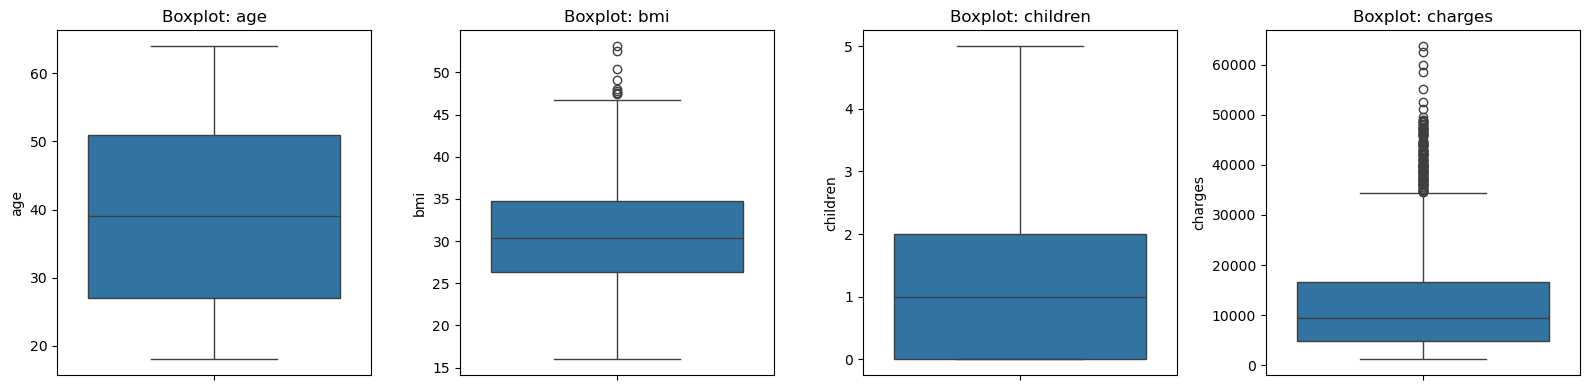

In [57]:

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, ax in zip(["age", "bmi", "children", "charges"], axes):
    sns.boxplot(y=s[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")

plt.tight_layout()
plt.show()

In [61]:
#Q7.build the multiple linear regression models
# 80% training data and 20% testing data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
model = s(steps=[("preprocessor", preprocessor),("regressor", LinearRegression())])
model.fit(X_train, y_train)
print("Model training completed successfully.")

NameError: name 'preprocessor' is not defined

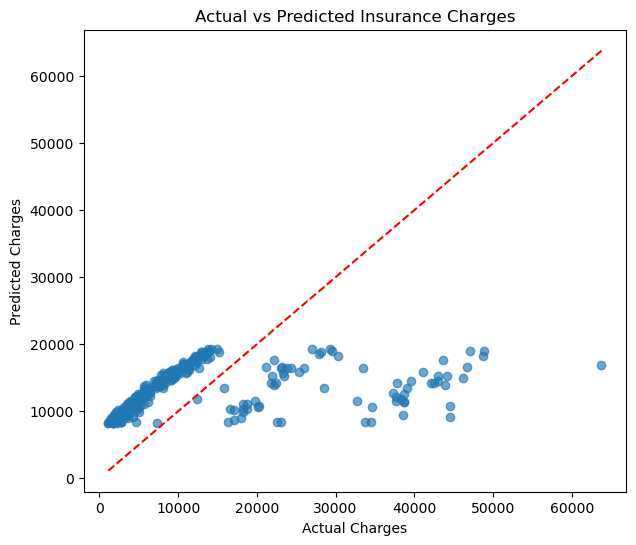

In [67]:
# Actual vs predicted plot

plt.figure(figsize=(7, 6))
plt.scatter(x=y_test, y=y_pred, alpha=0.65)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.show()